# Data Science Challenge

In [ ]:
# To install packages that are not installed by default, uncomment the last two lines 
# of this cell and replace <package list> with a list of necessary packages.
# This will ensure the notebook has all the dependencies and works everywhere.

#import sys
#!{sys.executable} -m pip install <package list>

In [1]:
#Libraries
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 101)

## Data Description

Column | Description
:---|:---
`id` | The unique ID assigned to every hotel.
`region` | The region in which the hotel is located..
`latitude` | The latitude of the hotel.
`longitude` | The longitude of the hotel.
`accommodation_type` | The type of accommodation offered by the hotel. For example: Private room, Entire house/apt, etc.
`cost` | The cost of booking the hotel for one night. (in \$\$)
`minimum_nights` | The minimum number of nights stay required.
`number_of_reviews` | The number of reviews accumulated by the hotel.
`reviews_per_month` | The average number of reviews received by the hotel per month.
`owner_id` | The unique ID assigned to every owner. An owner can own multiple hotels.
`owned_hotels` | The number of hotels owned by the owner.
`yearly_availability` | It indicates if the hotel accepts bookings around the year. Values are 0 (not available for 365 days in a year) and 1 (available for 365 days in a year).

## Data Wrangling & Visualization

- Drop any rows that are missing a value for a feature.
- Find and fix data bugs in the "region" and "accommodation_type" fields
- Add new features related to the original time-series variable.
- Use encoding of categorical features wherever it is necessary.
- Identify the features that are most important to the model's performance.


In [24]:
# Dataset is already loaded below
train = pd.read_json("train.json")
test = pd.read_csv("test.csv")


In [40]:
train.head()

,id,region,latitude,longitude,accommodation_type,cost,minimum_nights,number_of_reviews,reviews_per_month,owner_id,owned_hotels,yearly_availability
0,13232,Manhattan,40.71854,-74.00439,Entire home/apt,170,5,7,0.56,929983,1,0
1,246,Brooklyn,40.64446,-73.95030,Entire home/apt,65,3,238,2.30,281764,1,0
2,19091,Queens,40.78573,-73.81062,Privat room,85,1,0,NaN,19923341,1,1
3,34305,Manhattan,40.73863,-73.98002,Privat room,210,30,0,NaN,200380610,65,1
4,444,Manhattan,40.82426,-73.94630,Shared room,75,3,38,0.42,745069,3,1


In [41]:
#Explore columns
train.columns

Index(['id', 'region', 'latitude', 'longitude', 'accommodation_type', 'cost',
       'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'owner_id',
       'owned_hotels', 'yearly_availability'],
      dtype='object')

In [42]:
#Description
train.describe()

,id,latitude,longitude,cost,minimum_nights,number_of_reviews,reviews_per_month,owner_id,owned_hotels,yearly_availability
count,2870.000000,2870.000000,2870.000000,2870.000000,2870.000000,2870.000000,2194.000000,2.870000e+03,2870.000000,2870.000000
mean,26760.657143,40.731224,-73.950158,195.943206,11.530314,16.315331,1.157502,7.202195e+07,8.411498,0.498606
std,14140.930062,0.054942,0.049745,406.184714,37.972339,32.481722,1.355028,8.076516e+07,27.105522,0.500085
min,0.000000,40.507080,-74.242850,10.000000,1.000000,0.000000,0.010000,2.787000e+03,1.000000,0.000000
25%,15931.750000,40.692463,-73.984003,75.000000,1.000000,1.000000,0.240000,7.388002e+06,1.000000,0.000000
50%,28946.500000,40.728250,-73.956720,120.000000,3.000000,4.000000,0.650000,3.352708e+07,1.000000,0.000000
75%,38478.500000,40.762658,-73.934202,200.000000,6.000000,16.000000,1.530000,1.207625e+08,3.000000,1.000000
max,48893.000000,40.898730,-73.721730,9999.000000,999.000000,395.000000,10.370000,2.738123e+08,327.000000,1.000000


In [3]:
test.isna().sum()

id                      0
region                  0
latitude                0
longitude               0
accommodation_type      0
cost                    0
minimum_nights          0
number_of_reviews       0
reviews_per_month     173
owner_id                0
owned_hotels            0
dtype: int64

In [25]:
train = train.dropna().copy()
test = test.fillna(0)

### Check Skewness, Typo Fix, New features

In [46]:
# Skew analysis: decide on TRAIN, apply the same log columns to TRAIN and TEST
SKEW_THRESHOLD = 5.0
# EXCLUDE = ["id", "owner_id", "yearly_availability", "latitude", "longitude"]   # ids, target, coordinates

num_cols = ['cost', 'minimum_nights', 'number_of_reviews', 'reviews_per_month']
# num_cols = [c for c in data.select_dtypes("number").columns
#             if c not in EXCLUDE and data[c].nunique() > 2]                    # skip binary flags

skew_df = pd.DataFrame({
    "min": train[num_cols].min(),
    "max": train[num_cols].max(),
    "skew_raw": train[num_cols].skew(),
    "skew_log1p": train[num_cols].apply(lambda s: np.log1p(s).skew() if s.min() >= 0 else np.nan),
}).round(2).sort_values("skew_raw", key=abs, ascending=False)


skew_df

,min,max,skew_raw,skew_log1p
cost,10.00,8000.00,14.13,0.82
minimum_nights,1.00,500.00,11.93,1.72
number_of_reviews,1.00,395.00,3.82,0.42
reviews_per_month,0.01,10.37,2.16,0.91


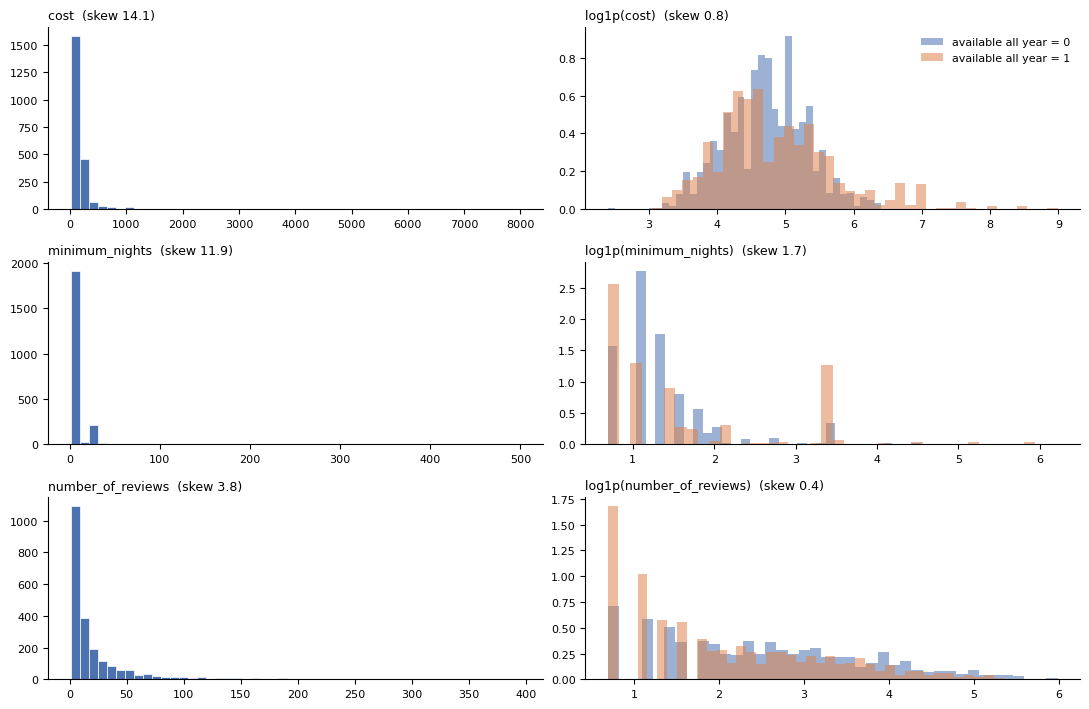

In [ ]:
import matplotlib.pyplot as plt

log_cols = ['cost', 'minimum_nights', 'number_of_reviews']
fig, axes = plt.subplots(len(log_cols), 2, figsize=(11, 2.4 * len(log_cols)))
for i, c in enumerate(log_cols):
    # Left: raw distribution
    axes[i, 0].hist(train[c], bins=50, color="#4C72B0", edgecolor="white", linewidth=0.5)
    axes[i, 0].set_title(f"{c}  (skew {data[c].skew():.1f})", fontsize=9, loc="left")
    # Right: log1p distribution, split by target
    for label, color in [(0, "#4C72B0"), (1, "#DD8452")]:
        vals = train.loc[train["yearly_availability"] == label, "log_" + c]
        axes[i, 1].hist(vals, bins=40, alpha=0.55, color=color,
                        label=f"available all year = {label}", density=True)
    axes[i, 1].set_title(f"log1p({c})  (skew {train['log_' + c].skew():.1f})", fontsize=9, loc="left")
axes[0, 1].legend(fontsize=8, frameon=False)
for ax in axes.ravel():
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.show()


In [26]:
def feature_fix(df):
    df['region'] = df['region'].str.lower().str.strip()
    df['region'] = df['region'].map(lambda s: 'Manhattan' if s.startswith('manh')
                                        else 'Brooklyn' if s.startswith('brook')
                                        else 'Queens' if s.startswith('queen')
                                        else 'Bronx' if s.startswith('bronx')
                                        else 'Staten Island' if s.startswith('staten')
                                        else '')
    df["accommodation_type"]  = df["accommodation_type"].str.lower().str.replace(r'\s+', ' ', regex=True)
    df["accommodation_type"] = df["accommodation_type"].map(lambda s: "Entire home/apt" if s.startswith("entire")
                                        else 'Private room' if s.startswith('priv') 
                                        else 'Shared room' if s.startswith('shar')
                                        else '')
    df['months_live'] = np.where(df["reviews_per_month"] > 0,
                                 df["number_of_reviews"] / df["reviews_per_month"],
                                 0)  

    log_cols = ['cost', 'minimum_nights', 'number_of_reviews']
    for c in log_cols:
        df['log_'+c] = np.log1p(df[c])
    
    df = df.drop(columns = log_cols+['owner_id', 'id'])
    return df


In [27]:
train = feature_fix(train)
test = feature_fix(test)

In [21]:
log_cols = ['cost', 'minimum_nights', 'number_of_reviews']
log_cols+['owner_id', 'id']

['cost', 'minimum_nights', 'number_of_reviews', 'owner_id', 'id']

In [28]:
CAT_COLS = ["region", "accommodation_type"]

X_train = pd.get_dummies(train, columns=CAT_COLS)
X_test = pd.get_dummies(test, columns=CAT_COLS)
# Force test to have exactly the train columns (missing ones -> 0, extra ones dropped)
X_test = X_test.reindex(columns=X_train.columns.drop("yearly_availability"), fill_value=0)


In [17]:
[c for c in X_test.columns if X_test[c].nunique() <= 1]

[]

### Features Correlation

accommodation_type_Entire home/apt   -0.663572
accommodation_type_Private room       0.615238
reviews_per_month                    -0.250670
owned_hotels                          0.233727
months_live                           0.206710
log_number_of_reviews                -0.176075
longitude                             0.166287
log_minimum_nights                    0.130778
region_Queens                         0.119851
log_cost                              0.096943
accommodation_type_Shared room        0.092821
region_Bronx                          0.082254
region_Manhattan                     -0.065128
region_Brooklyn                      -0.044728
latitude                             -0.031903
region_Staten Island                  0.017733
Name: yearly_availability, dtype: float64


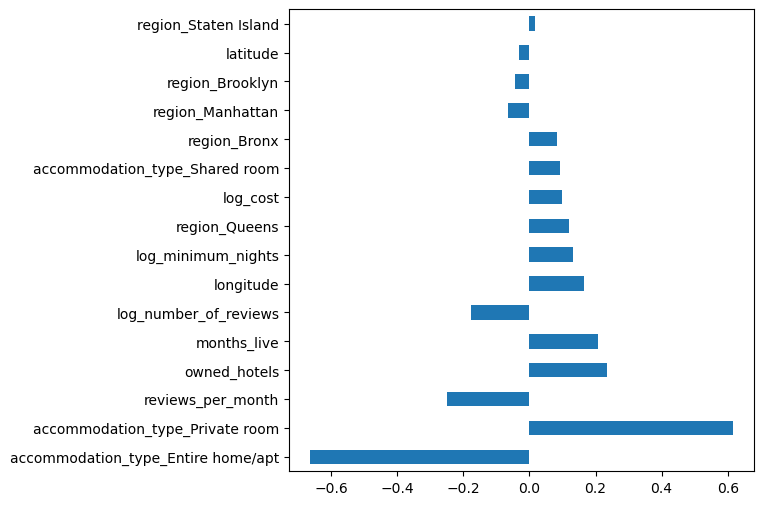

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

TARGET = 'yearly_availability'
corr_target = X_train.corr()[TARGET].drop(TARGET)
corr_target = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index)
print(corr_target)
corr_target.plot.barh(figsize=(6, 6))
plt.show()


**EDA conclusions**
- Accommodation type is the strongest signal: most Private rooms are available all year, while Entire home/apt listings rarely are.
- The larger `owned_hotels` (professional hosts), the more likely a listing is available all year.
- More frequent reviews (high `reviews_per_month`) → less likely to be available all year (often booked out, or the host lives there part of the time).
- `cost`, `minimum_nights` and `owned_hotels` are heavily right-skewed → apply log.

In [37]:
y_all = train["yearly_availability"]
for c in ["accommodation_type", "region"]:
    print(train.groupby(c)["yearly_availability"].agg(["mean", "size"]).round(3), "\n")
for c in ["log_minimum_nights", "log_cost", "log_number_of_reviews", "reviews_per_month", "owned_hotels"]:
    print(train.groupby(pd.qcut(train[c], 5, duplicates="drop"))["yearly_availability"].mean().round(3), "\n")

                     mean  size
accommodation_type             
Entire home/apt     0.044   954
Private room        0.848   728
Shared room         0.500   512 

                mean  size
region                    
Bronx          0.661    59
Brooklyn       0.390   889
Manhattan      0.381   959
Queens         0.571   282
Staten Island  0.600     5 

log_minimum_nights
(0.692, 1.099]    0.431
(1.099, 1.386]    0.301
(1.386, 1.792]    0.241
(1.792, 6.217]    0.599
Name: yearly_availability, dtype: float64 

log_cost
(2.3970000000000002, 4.19]    0.443
(4.19, 4.564]                 0.426
(4.564, 4.913]                0.336
(4.913, 5.303]                0.334
(5.303, 8.987]                0.573
Name: yearly_availability, dtype: float64 

log_number_of_reviews
(0.692, 1.099]    0.567
(1.099, 1.823]    0.438
(1.823, 2.565]    0.380
(2.565, 3.434]    0.359
(3.434, 5.981]    0.320
Name: yearly_availability, dtype: float64 

reviews_per_month
(0.009000000000000001, 0.19]    0.690
(0.19, 0.46] 

Empty DataFrame
Columns: [level_0, level_1, rho]
Index: []


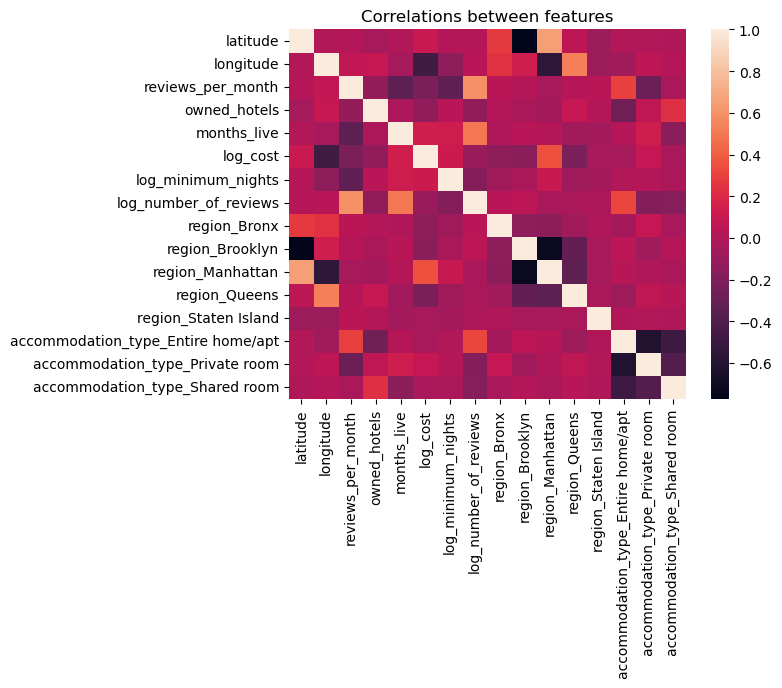

In [42]:
## Collinearity
# Feature-vs-feature pairs with |rho| > 0.8 are near-duplicates (keep one)
feat_corr = X_train.drop(columns=TARGET).corr(method="spearman")
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
         .stack().rename("rho").reset_index()
         .query("abs(rho) > 0.8").sort_values("rho", key=abs, ascending=False))
print(pairs.round(3).to_string(index=False))

ax = plt.axes()
sns.heatmap(feat_corr,ax = ax)
ax.set_title("Correlations between features")
plt.show()

### Important Features

In [39]:
corr_target.index

Index(['accommodation_type_Entire home/apt', 'accommodation_type_Private room',
       'reviews_per_month', 'owned_hotels', 'months_live',
       'log_number_of_reviews', 'longitude', 'log_minimum_nights',
       'region_Queens', 'log_cost', 'accommodation_type_Shared room',
       'region_Bronx', 'region_Manhattan', 'region_Brooklyn', 'latitude',
       'region_Staten Island'],
      dtype='object')

     k                               added  LogReg  LogReg_sd  RandomForest  \
0    1  accommodation_type_Entire home/apt   0.814      0.016         0.814   
1    2     accommodation_type_Private room   0.807      0.016         0.807   
2    3                   reviews_per_month   0.809      0.025         0.807   
3    4                        owned_hotels   0.869      0.014         0.906   
4    5                         months_live   0.878      0.016         0.916   
5    6               log_number_of_reviews   0.875      0.016         0.918   
6    7                           longitude   0.881      0.014         0.921   
7    8                  log_minimum_nights   0.879      0.017         0.923   
8    9                       region_Queens   0.880      0.014         0.923   
9   10                            log_cost   0.880      0.016         0.926   
10  11      accommodation_type_Shared room   0.880      0.017         0.926   
11  12                        region_Bronx   0.880  

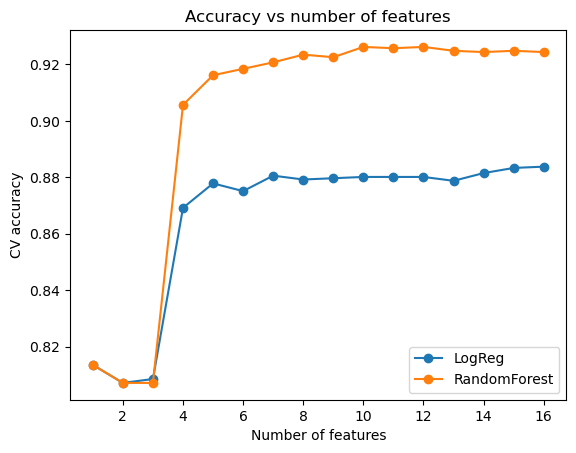

LogReg best k: 16 | smallest good k: 5
['accommodation_type_Entire home/apt', 'accommodation_type_Private room', 'reviews_per_month', 'owned_hotels', 'months_live']
RandomForest best k: 12 | smallest good k: 5
['accommodation_type_Entire home/apt', 'accommodation_type_Private room', 'reviews_per_month', 'owned_hotels', 'months_live']


In [43]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

X_all = X_train.drop(columns=TARGET)
y = X_train[TARGET]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1),
}

# Add features one at a time in order of |correlation| and track CV accuracy
feats = corr_target.index.tolist()
res = []
for k in range(1, len(feats) + 1):
    r = {"k": k, "added": feats[k-1]}
    for name, m in models.items():
        s = cross_val_score(m, X_all[feats[:k]], y, cv=cv)
        r[name] = s.mean()
        r[name + "_sd"] = s.std()
    res.append(r)
curve = pd.DataFrame(res)
print(curve.round(3))

# Plot accuracy vs number of features
for name in models:
    plt.plot(curve["k"], curve[name], marker="o", label=name)
plt.xlabel("Number of features")
plt.ylabel("CV accuracy")
plt.title("Accuracy vs number of features")
plt.legend()
plt.show()

# Smallest k within 1 std of the best score
for name in models:
    i = curve[name].idxmax()
    cut = curve.loc[i, name] - curve.loc[i, name + "_sd"]
    k = curve.loc[curve[name] >= cut, "k"].min()
    print(name, "best k:", curve.loc[i, "k"], "| smallest good k:", k)
    print(feats[:k])


## Visualization, Modeling, Machine Learning

Build a model that categorizes hotels on the basis of their yearly availability. Identify how different features influence the decision. Please explain the findings effectively to technical and non-technical audiences using comments and visualizations, if appropriate.
- **Build an optimized model that effectively solves the business problem.**
- **The model will be evaluated on the basis of Accuracy.**
- **Read the test.csv file and prepare features for testing.**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

best_feats = feats[:12]
print("Features used:", best_feats)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)

# 1) CV score of the final setup
s = cross_val_score(rf, X_all[best_feats], y, cv=cv)
print(f"5-fold CV accuracy: {s.mean():.3f} +/- {s.std():.3f}")

# 2) Hold-out check: precision / recall / confusion matrix
X_a, X_v, y_a, y_v = train_test_split(X_all[best_feats], y, test_size=0.25, stratify=y, random_state=0)
rf.fit(X_a, y_a)
pred_v = rf.predict(X_v)
print(classification_report(y_v, pred_v, digits=3))
print(confusion_matrix(y_v, pred_v))




Features used: ['accommodation_type_Entire home/apt', 'accommodation_type_Private room', 'reviews_per_month', 'owned_hotels', 'months_live', 'log_number_of_reviews', 'longitude', 'log_minimum_nights', 'region_Queens', 'log_cost', 'accommodation_type_Shared room', 'region_Bronx']
5-fold CV accuracy: 0.926 +/- 0.013
              precision    recall  f1-score   support

           0      0.958     0.934     0.946       320
           1      0.911     0.943     0.927       229

    accuracy                          0.938       549
   macro avg      0.935     0.939     0.937       549
weighted avg      0.939     0.938     0.938       549

[[299  21]
 [ 13 216]]
0    367
1    351
Name: yearly_availability, dtype: int64


,id,yearly_availability
0,19215,0
1,36301,0
2,40566,1
3,33694,0
4,28873,0


“Logistic regression gives an interpretable linear baseline; random forest captures non-linear effects and interactions between location, room type and pricing. We compare them with 5-fold cross-validation and choose the model with the best out-of-fold F1/accuracy.”

In [48]:
print(confusion_matrix(y_v, pred_v))

[[299  21]
 [ 13 216]]


Confusion matrix: 21 false positives and 13 false negatives out of 549. The errors lean toward over-predicting "available all year".


In [ ]:
#Loading Test data
test_data=pd.read_csv('test.csv')
test_data.head()

In [ ]:
# 3) Final model: new model on ALL training rows, predict test (rf stays the hold-out model)
final_rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1)
final_rf.fit(X_all[best_feats], y)
test_pred = final_rf.predict(X_test[best_feats])

# feature_fix dropped 'id', so take ids from the original file (row order is unchanged)
test_ids = pd.read_csv("test.csv")["id"]
submission_df = pd.DataFrame({"id": test_ids, "yearly_availability": test_pred.astype(int)})

assert len(submission_df) == len(test_ids)
assert submission_df.notna().all().all()
print(submission_df["yearly_availability"].value_counts())
submission_df.head()

**Highlight the most important features of the model for management.**

> #### Task:
- **Visualize the top 20 features and their feature importance.**

                           feature  perm_importance  perm_std  rf_importance        direction
   accommodation_type_Private room            0.113     0.009          0.204 + more available
accommodation_type_Entire home/apt            0.109     0.011          0.250 - less available
                      owned_hotels            0.104     0.008          0.159 + more available
                 reviews_per_month            0.011     0.003          0.071 - less available
                          log_cost            0.009     0.003          0.047 + more available
                       months_live            0.009     0.003          0.066 + more available
                         longitude            0.009     0.004          0.050 + more available
             log_number_of_reviews            0.006     0.003          0.057 - less available
                log_minimum_nights            0.004     0.003          0.037 + more available
                     region_Queens            0.001     0.00

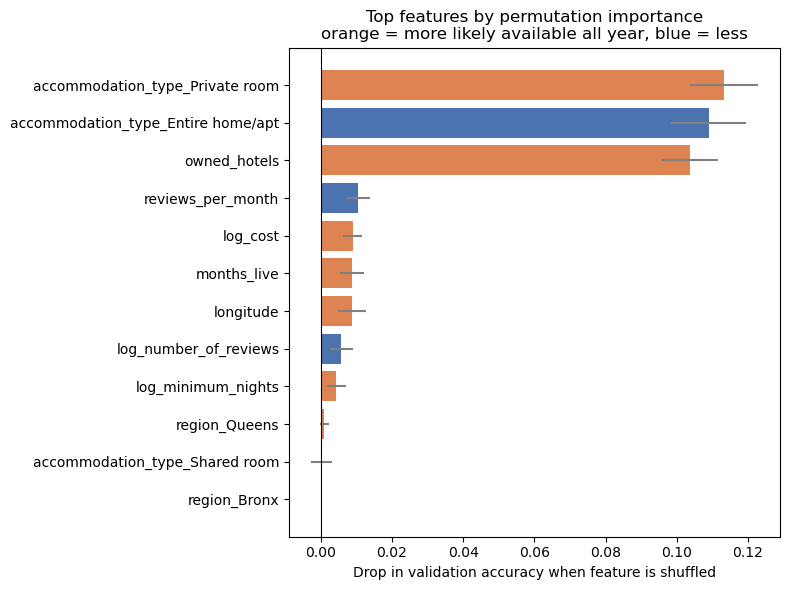

In [ ]:
from sklearn.inspection import permutation_importance
##Permutation importance measures how much a model's score drops when you scramble one feature. If the model relies on that feature, 
# Permutation importance on the validation set: drop in accuracy when a feature is shuffled

y_prob = rf.predict_proba(X_v)[:, 1]   # rf = hold-out model trained on X_a in cell 30
perm = permutation_importance(rf, X_v, y_v, scoring="accuracy", n_repeats=20, random_state=0, n_jobs=-1)

imp = pd.DataFrame({
    "feature": best_feats,
    "perm_importance": perm.importances_mean,
    "perm_std": perm.importances_std,
    "rf_importance": rf.feature_importances_,                      # impurity-based, for comparison
    "direction": ["+ more available" if X_v[f].corr(pd.Series(y_prob, index=X_v.index)) > 0
                  else "- less available" for f in best_feats],
}).sort_values("perm_importance", ascending=False).head(20)
print(imp.round(3).to_string(index=False))

# Plot (top 20, or all if fewer); orange = pushes toward "available all year", blue = away
top = imp.iloc[::-1]
colors = ["#DD8452" if d.startswith("+") else "#4C72B0" for d in top["direction"]]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["perm_importance"], xerr=top["perm_std"], color=colors, ecolor="gray")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Drop in validation accuracy when feature is shuffled")
plt.title("Top features by permutation importance\norange = more likely available all year, blue = less")
plt.tight_layout()
plt.show()


What makes a hotel available all year?

What is rented. Private rooms are almost always open; entire homes almost never are. Entire homes are usually someone's own place, rented out occasionally.
Who rents it. Hosts managing many listings run them as a business and keep them open year-round.
How busy it is. Listings reviewed often are frequently booked, so fewer days remain open.
Price, location and minimum stay matter very little. Recommendation: to find hotels that accept bookings all year, focus on private rooms run by multi-listing hosts.

> #### Task:
- **Submit the predictions on the test dataset using your optimized model** <br/>
    For each record in the test set (`test.csv`), predict the value of the `yearly_availability` variable. Submit a CSV file with a header row and one row per test entry.

The file (`submissions.csv`) should have exactly 2 columns:
   - **id**
   - **yearly_availability**

In [ ]:
#Submission
submission_df.to_csv('submissions.csv',index=False)

---